# Notebook 3 — Models, evaluation and export

**Goal:** train and fairly evaluate

1. the **condition model** (neutral / interruptions / time_pressure), and
2. the **load model** (low / high self-rated mental effort),

then export the final models for the desktop agent.

**How we evaluate (headline): leave-one-subject-out (LOSO).** Train on 24 people, test on the 25th, repeat for
all 25. Hyperparameters are tuned **inside the training people only** (`GroupKFold` over the 24 training
participants), never on the test person. We report macro-F1 (headline), balanced accuracy and accuracy as
mean ± standard deviation over the 25 folds, always next to the majority-class baseline.

**Input:** `ml/data/processed/swell_features_*.csv` (Notebook 2).
**Outputs:** tables and charts in `ml/reports/`; `condition_model.pkl`, `load_model.pkl`, `features.json`,
`model_card.md` in `shared/models/`.

*Runtime:* about 15–30 minutes on a laptop (many cross-validation runs).

In [1]:
# --- Find the project folder so the notebook works from any working directory ---
import sys
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    """Walk up from `start` until we find the folder that contains shared/features.py."""
    for folder in [start, *start.parents]:
        if (folder / "shared" / "features.py").exists():
            return folder
    raise FileNotFoundError("Could not find the Commit project folder (shared/features.py).")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
sys.path.insert(0, str(REPO_ROOT))  # lets us "import shared.features"

RAW_DIR = REPO_ROOT / "ml" / "data" / "raw"
PROCESSED_DIR = REPO_ROOT / "ml" / "data" / "processed"
REPORTS_DIR = REPO_ROOT / "ml" / "reports"
MODELS_DIR = REPO_ROOT / "shared" / "models"
for folder in (PROCESSED_DIR, REPORTS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Project folder:", REPO_ROOT)

Project folder: /Users/matrix/Desktop/Commit


In [2]:
import json
import platform
import time
import warnings
from datetime import date

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
from lightgbm import LGBMClassifier
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, GroupKFold, LeaveOneGroupOut, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from shared import features as F

# Hide repeated library warnings (e.g. "y_pred contains classes not in y_true" in a single
# test person). They do not change any result and would bury the output.
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)

In [3]:
# --- Settings ---

RANDOM_SEED = 42            # makes random splits and models repeatable
INNER_FOLDS = 5             # folds used for tuning inside the training data
RANDOM_CV_FOLDS = 10        # folds for the (over-optimistic) random cross-validation comparison
CALIBRATION_ACTIVE_MINUTES = 15   # must match Notebook 2 and the app's calibration period

FEATURE_NAMES = F.model_feature_names(F.DEFAULT_ROLLING_WINDOWS)

# Main load label (decided before looking at results): the per-person median split, because
# the app's load score is personal (it is later calibrated to the user's own check-ins).
MAIN_LOAD_LABEL = "load_person_median"
ALL_LOAD_LABELS = ["load_person_median", "load_overall_median"]

# SHAP is slow on many rows; explain a random sample of this many rows.
SHAP_SAMPLE_ROWS = 500
SHAP_BACKGROUND_ROWS = 100   # background rows for non-tree models
SHAP_TOP_FEATURES = 15       # features shown in each SHAP chart

# Participants whose interruption block is doubtful (see ml/README.md): they did not see the e-mails.
DOUBTFUL_INTERRUPTION_PARTICIPANTS = ["PP12", "PP21"]

## 1. Load the feature tables

In [4]:
def load_feature_table(variant: str) -> pd.DataFrame:
    """
    Load one feature variant saved by Notebook 2 and keep only the modelling rows.

    In:  "raw", "calibration" or "neutral".
    Out: rows with in_evaluation == True (active, non-calibration minutes), index reset.
    """
    table = pd.read_csv(PROCESSED_DIR / f"swell_features_{variant}.csv", parse_dates=["timestamp"])
    return table[table["in_evaluation"]].reset_index(drop=True)


tables = {variant: load_feature_table(variant) for variant in ["calibration", "raw", "neutral"]}
main_table = tables["calibration"]

# All three variants must contain exactly the same rows in the same order.
for variant, table in tables.items():
    assert table[["participant", "timestamp"]].equals(main_table[["participant", "timestamp"]]), variant

print("Modelling rows:", len(main_table), " participants:", main_table["participant"].nunique())
print(main_table["condition"].value_counts().to_string())

Modelling rows: 2243  participants: 25
condition
interruptions    951
time_pressure    662
neutral          630


## 2. Models and hyperparameter grids

| Name | Model | Tuned |
|---|---|---|
| majority | always predicts the most common class (baseline) | – |
| logistic_regression | linear baseline (features standardised) | C |
| random_forest | 200 trees | min_samples_leaf |
| lightgbm | gradient-boosted trees, 200 rounds | num_leaves, min_child_samples |
| svm_rbf | support vector machine, RBF kernel (features standardised) | C |

All real models use `class_weight="balanced"` so the smaller classes are not ignored.
Grids are deliberately small to keep the runtime reasonable.

In [5]:
MODEL_NAMES = ["majority", "logistic_regression", "random_forest", "lightgbm", "svm_rbf"]

PARAMETER_GRIDS = {
    "majority": {},
    "logistic_regression": {"model__C": [0.01, 0.1, 1.0]},
    "random_forest": {"model__min_samples_leaf": [1, 5, 20]},
    "lightgbm": {"model__num_leaves": [7, 31], "model__min_child_samples": [20, 50]},
    "svm_rbf": {"model__C": [0.1, 1.0, 10.0]},
}


def make_pipeline(model_name: str, for_export: bool = False) -> Pipeline:
    """
    Create an untrained model pipeline.

    In:  model name (see table above); for_export=True makes the SVM able to output
         probabilities (slower, only needed for the final app model).
    Out: a scikit-learn Pipeline whose last step is called "model".
    Why: one place that defines every model keeps all experiments consistent.
    """
    if model_name == "majority":
        return Pipeline([("model", DummyClassifier(strategy="most_frequent"))])
    if model_name == "logistic_regression":
        model = LogisticRegression(max_iter=2000, class_weight="balanced")
        return Pipeline([("scale", StandardScaler()), ("model", model)])
    if model_name == "random_forest":
        model = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_SEED, n_jobs=1)
        return Pipeline([("model", model)])
    if model_name == "lightgbm":
        model = LGBMClassifier(n_estimators=200, learning_rate=0.05, class_weight="balanced",
                               random_state=RANDOM_SEED, n_jobs=1, verbose=-1)
        return Pipeline([("model", model)])
    if model_name == "svm_rbf":
        model = SVC(kernel="rbf", gamma="scale", class_weight="balanced",
                    probability=for_export, random_state=RANDOM_SEED)
        return Pipeline([("scale", StandardScaler()), ("model", model)])
    raise ValueError(f"Unknown model: {model_name}")

## 3. Cross-validation helpers

In [6]:
def fit_tuned_model(model_name, X_train, y_train, inner_cv, inner_groups=None, for_export=False):
    """
    Tune hyperparameters on the TRAINING data only, then refit on all training data.

    In:  model name, training features and labels, the inner splitter, and the participant
         of each training row (needed by GroupKFold; None for random splits).
    Out: (fitted pipeline, chosen hyperparameters as a dict).
    Why: tuning on the test person would leak information and inflate the scores.
    """
    grid = PARAMETER_GRIDS[model_name]
    pipeline = make_pipeline(model_name, for_export)
    if not grid:
        return pipeline.fit(X_train, y_train), {}
    search = GridSearchCV(pipeline, grid, cv=inner_cv, scoring="f1_macro", n_jobs=-1)
    search.fit(X_train, y_train, groups=inner_groups)
    return search.best_estimator_, search.best_params_


def cross_validate(model_name, X, y, groups, scheme):
    """
    Run one complete outer cross-validation and collect every test prediction.

    In:  model name, features X, labels y, participant of each row, and the scheme:
         "loso"   = leave one participant out (tuning with GroupKFold on the other 24), or
         "random" = random stratified 10-fold (tuning with random 5-fold) — for comparison only.
    Out: DataFrame with one row per test minute: fold, participant, true, predicted;
         and a list of the hyperparameters chosen in each fold.
    """
    if scheme == "loso":
        outer_splits = LeaveOneGroupOut().split(X, y, groups)
        inner_cv = GroupKFold(n_splits=INNER_FOLDS)
    else:
        outer_splits = StratifiedKFold(RANDOM_CV_FOLDS, shuffle=True, random_state=RANDOM_SEED).split(X, y)
        inner_cv = StratifiedKFold(INNER_FOLDS, shuffle=True, random_state=RANDOM_SEED)

    prediction_parts, chosen_parameters = [], []
    for fold, (train_index, test_index) in enumerate(outer_splits):
        inner_groups = groups.iloc[train_index] if scheme == "loso" else None
        model, parameters = fit_tuned_model(model_name, X.iloc[train_index], y.iloc[train_index], inner_cv, inner_groups)
        chosen_parameters.append(parameters)
        prediction_parts.append(pd.DataFrame({
            "fold": fold,
            "participant": groups.iloc[test_index].to_numpy(),
            "true": y.iloc[test_index].to_numpy(),
            "predicted": model.predict(X.iloc[test_index]),
        }))
    return pd.concat(prediction_parts, ignore_index=True), chosen_parameters


def scores_per_fold(predictions: pd.DataFrame) -> pd.DataFrame:
    """
    Compute macro-F1, balanced accuracy and accuracy for every fold.

    In:  predictions from cross_validate.
    Out: one row per fold (for LOSO: one row per test participant).
    Note: macro-F1 averages over the classes that appear in that fold (true or predicted).
    """
    rows = []
    for fold, part in predictions.groupby("fold"):
        rows.append({
            "fold": fold,
            "participant": part["participant"].iloc[0] if part["participant"].nunique() == 1 else "mixed",
            "macro_f1": f1_score(part["true"], part["predicted"], average="macro", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(part["true"], part["predicted"]),
            "accuracy": accuracy_score(part["true"], part["predicted"]),
        })
    return pd.DataFrame(rows)


def summarise(predictions: pd.DataFrame, **labels) -> dict:
    """
    Summarise one cross-validation run as mean ± std over folds.

    In:  predictions and extra descriptive fields (e.g. model="lightgbm", scheme="loso").
    Out: a dict, ready to become one row of a results table.
    """
    per_fold = scores_per_fold(predictions)
    summary = dict(labels)
    for metric in ["macro_f1", "balanced_accuracy", "accuracy"]:
        summary[f"{metric}_mean"] = per_fold[metric].mean()
        summary[f"{metric}_std"] = per_fold[metric].std()
    summary["folds"] = len(per_fold)
    return summary


def run_experiment(model_name, table, target, scheme, feature_names=FEATURE_NAMES, **labels):
    """
    Convenience wrapper: cross-validate one model on one table/target and print the result.

    Out: (summary dict, predictions DataFrame, chosen hyperparameters per fold).
    """
    start = time.time()
    predictions, parameters = cross_validate(
        model_name, table[feature_names], table[target], table["participant"], scheme
    )
    summary = summarise(predictions, model=model_name, scheme=scheme, target=target, **labels)
    print(f"{model_name:20s} {scheme:6s} {target:20s} macro-F1 = {summary['macro_f1_mean']:.3f} "
          f"± {summary['macro_f1_std']:.3f}   ({time.time() - start:.0f} s)")
    return summary, predictions, parameters


def format_mean_std(results: pd.DataFrame, metric: str) -> pd.Series:
    """Format "mean ± std" text for a metric column pair (for readable tables)."""
    return results[f"{metric}_mean"].map("{:.3f}".format) + " ± " + results[f"{metric}_std"].map("{:.3f}".format)

## 4. Condition model — all models, LOSO and random 10-fold

Random 10-fold CV puts minutes of the **same person** in both training and test sets, so the model can
partly recognise the person instead of the condition. Comparing it with LOSO shows how much random splits
over-estimate performance on new people.

In [7]:
condition_results, condition_predictions, condition_parameters = [], {}, {}
for model_name in MODEL_NAMES:
    for scheme in ["loso", "random"]:
        summary, predictions, parameters = run_experiment(model_name, main_table, "condition", scheme)
        condition_results.append(summary)
        condition_predictions[(model_name, scheme)] = predictions
        condition_parameters[(model_name, scheme)] = parameters

condition_results = pd.DataFrame(condition_results)
condition_results.to_csv(REPORTS_DIR / "condition_results.csv", index=False)

majority             loso   condition            macro-F1 = 0.197 ± 0.018   (0 s)
majority             random condition            macro-F1 = 0.198 ± 0.000   (0 s)


logistic_regression  loso   condition            macro-F1 = 0.350 ± 0.103   (5 s)


logistic_regression  random condition            macro-F1 = 0.438 ± 0.028   (1 s)


random_forest        loso   condition            macro-F1 = 0.398 ± 0.103   (95 s)


random_forest        random condition            macro-F1 = 0.820 ± 0.039   (38 s)


lightgbm             loso   condition            macro-F1 = 0.380 ± 0.106   (109 s)


lightgbm             random condition            macro-F1 = 0.846 ± 0.031   (46 s)


svm_rbf              loso   condition            macro-F1 = 0.385 ± 0.116   (17 s)


svm_rbf              random condition            macro-F1 = 0.660 ± 0.027   (6 s)


In [8]:
# Side-by-side table: LOSO vs random 10-fold.
def loso_vs_random_table(results: pd.DataFrame) -> pd.DataFrame:
    """Pivot a results table into one row per model with LOSO and random columns."""
    table = pd.DataFrame({"model": MODEL_NAMES})
    for scheme in ["loso", "random"]:
        part = results[results["scheme"] == scheme].set_index("model").reindex(MODEL_NAMES)
        table[f"{scheme}_macro_f1"] = format_mean_std(part, "macro_f1").to_numpy()
        table[f"{scheme}_balanced_acc"] = format_mean_std(part, "balanced_accuracy").to_numpy()
        table[f"{scheme}_accuracy"] = format_mean_std(part, "accuracy").to_numpy()
    loso = results[results["scheme"] == "loso"].set_index("model").reindex(MODEL_NAMES)
    random = results[results["scheme"] == "random"].set_index("model").reindex(MODEL_NAMES)
    table["inflation_macro_f1"] = (random["macro_f1_mean"] - loso["macro_f1_mean"]).round(3).to_numpy()
    return table


condition_table = loso_vs_random_table(condition_results)
condition_table.to_csv(REPORTS_DIR / "condition_loso_vs_random.csv", index=False)

# The best model is the real model (not the baseline) with the highest mean LOSO macro-F1.
loso_condition = condition_results[(condition_results["scheme"] == "loso") & (condition_results["model"] != "majority")]
BEST_CONDITION_MODEL = loso_condition.sort_values("macro_f1_mean", ascending=False)["model"].iloc[0]
print("Best condition model (LOSO macro-F1):", BEST_CONDITION_MODEL)
condition_table

Best condition model (LOSO macro-F1): random_forest


,model,loso_macro_f1,loso_balanced_acc,loso_accuracy,random_macro_f1,random_balanced_acc,random_accuracy,inflation_macro_f1
0,majority,0.197 ± 0.018,0.333 ± 0.000,0.421 ± 0.051,0.198 ± 0.000,0.333 ± 0.000,0.424 ± 0.001,0.001
1,logistic_regression,0.350 ± 0.103,0.396 ± 0.099,0.386 ± 0.107,0.438 ± 0.028,0.454 ± 0.032,0.446 ± 0.029,0.088
2,random_forest,0.398 ± 0.103,0.433 ± 0.106,0.422 ± 0.120,0.820 ± 0.039,0.824 ± 0.039,0.823 ± 0.039,0.423
3,lightgbm,0.380 ± 0.106,0.412 ± 0.105,0.402 ± 0.118,0.846 ± 0.031,0.848 ± 0.030,0.848 ± 0.031,0.467
4,svm_rbf,0.385 ± 0.116,0.410 ± 0.106,0.413 ± 0.121,0.660 ± 0.027,0.669 ± 0.025,0.665 ± 0.027,0.275


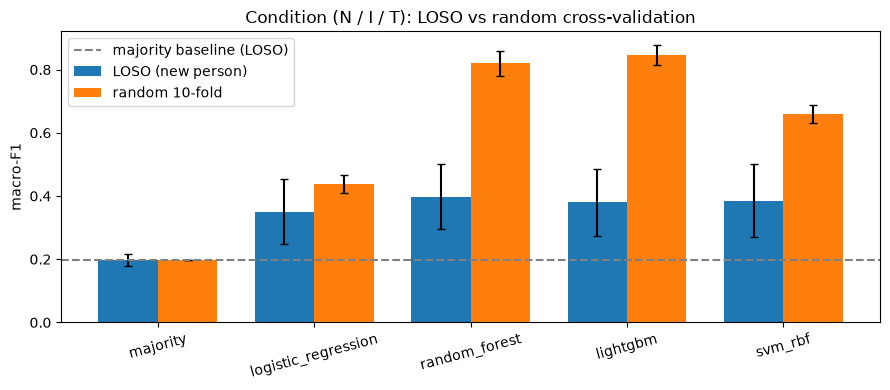

In [9]:
# Chart: LOSO vs random macro-F1 per model, with the majority baseline as a dashed line.
figure, axis = plt.subplots(figsize=(9, 4))
positions = np.arange(len(MODEL_NAMES))
bar_width = 0.38
for offset, scheme in [(-bar_width / 2, "loso"), (bar_width / 2, "random")]:
    part = condition_results[condition_results["scheme"] == scheme].set_index("model").reindex(MODEL_NAMES)
    axis.bar(positions + offset, part["macro_f1_mean"], bar_width, yerr=part["macro_f1_std"], capsize=3,
             label="LOSO (new person)" if scheme == "loso" else "random 10-fold")
majority_loso = condition_results.query("model == 'majority' and scheme == 'loso'")["macro_f1_mean"].iloc[0]
axis.axhline(majority_loso, linestyle="--", color="grey", label="majority baseline (LOSO)")
axis.set_xticks(positions, labels=MODEL_NAMES, rotation=15)
axis.set_ylabel("macro-F1")
axis.set_title("Condition (N / I / T): LOSO vs random cross-validation")
axis.legend()
figure.tight_layout()
figure.savefig(REPORTS_DIR / "condition_loso_vs_random.png", dpi=150)
plt.show()

### Confusion matrices and per-participant scores (best model)

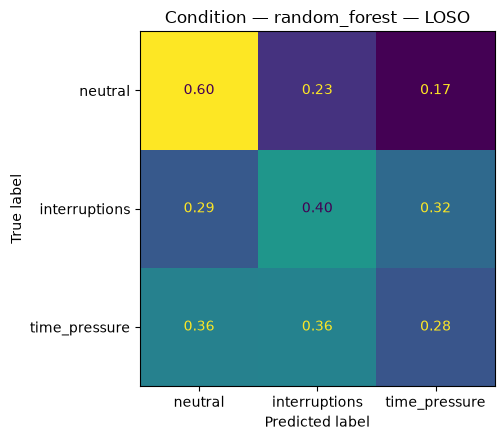

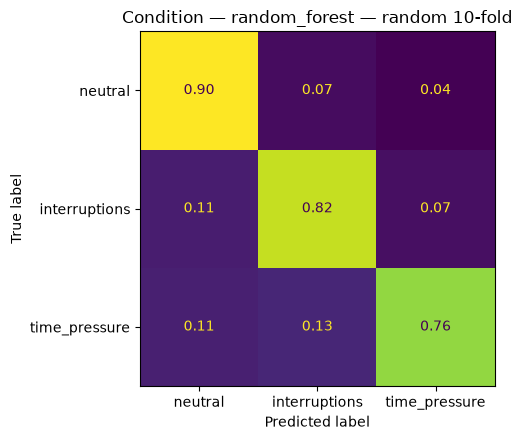

In [10]:
def plot_confusion(predictions: pd.DataFrame, class_order: list, title: str, file_name: str) -> None:
    """
    Plot a row-normalised confusion matrix (each row sums to 1) of all pooled test predictions.

    In:  predictions, the class order for the axes, a title and the output file name.
    Out: shows the chart and saves it to ml/reports/.
    """
    figure, axis = plt.subplots(figsize=(5.5, 4.5))
    ConfusionMatrixDisplay.from_predictions(
        predictions["true"], predictions["predicted"], labels=class_order,
        normalize="true", values_format=".2f", ax=axis, colorbar=False,
    )
    axis.set_title(title)
    figure.tight_layout()
    figure.savefig(REPORTS_DIR / file_name, dpi=150)
    plt.show()


CONDITION_CLASSES = ["neutral", "interruptions", "time_pressure"]
plot_confusion(condition_predictions[(BEST_CONDITION_MODEL, "loso")], CONDITION_CLASSES,
               f"Condition — {BEST_CONDITION_MODEL} — LOSO", "condition_confusion_loso.png")
plot_confusion(condition_predictions[(BEST_CONDITION_MODEL, "random")], CONDITION_CLASSES,
               f"Condition — {BEST_CONDITION_MODEL} — random 10-fold", "condition_confusion_random.png")

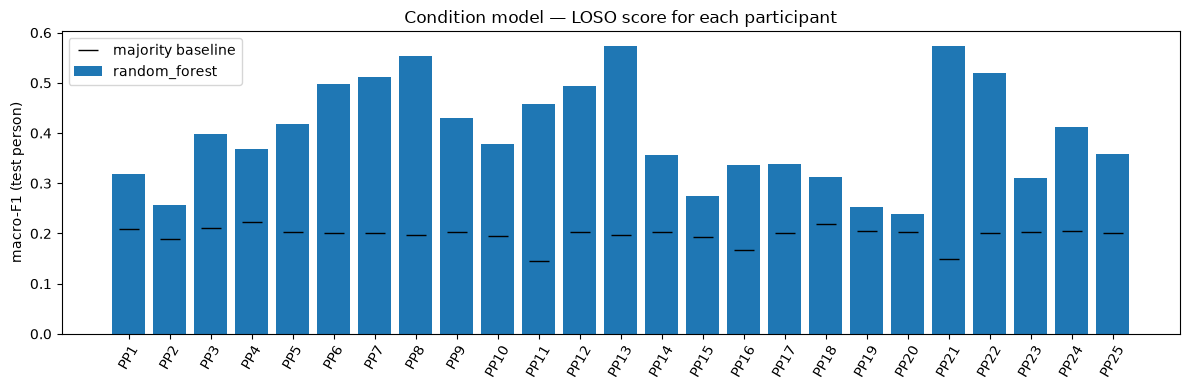

Participants where the model beats the majority baseline: 25 of 25
Doubtful interruption participants:
             macro_f1  balanced_accuracy  accuracy  majority_macro_f1
participant                                                          
PP12            0.495              0.510     0.542              0.203
PP21            0.573              0.613     0.603              0.149


In [11]:
def per_participant_table(model_predictions: pd.DataFrame, baseline_predictions: pd.DataFrame) -> pd.DataFrame:
    """
    LOSO scores for each test participant, for a model and for the majority baseline.

    In:  LOSO predictions of the model and of the majority baseline.
    Out: one row per participant, sorted by participant number.
    """
    model_scores = scores_per_fold(model_predictions).set_index("participant")
    baseline_scores = scores_per_fold(baseline_predictions).set_index("participant")
    table = model_scores[["macro_f1", "balanced_accuracy", "accuracy"]].copy()
    table["majority_macro_f1"] = baseline_scores["macro_f1"]
    order = sorted(table.index, key=lambda name: int(name[2:]))
    return table.loc[order]


condition_per_participant = per_participant_table(
    condition_predictions[(BEST_CONDITION_MODEL, "loso")], condition_predictions[("majority", "loso")]
)
condition_per_participant.to_csv(REPORTS_DIR / "condition_per_participant.csv")

figure, axis = plt.subplots(figsize=(12, 4))
axis.bar(condition_per_participant.index, condition_per_participant["macro_f1"], label=BEST_CONDITION_MODEL)
axis.plot(condition_per_participant.index, condition_per_participant["majority_macro_f1"], "k_", markersize=14, label="majority baseline")
axis.set_ylabel("macro-F1 (test person)")
axis.set_title("Condition model — LOSO score for each participant")
axis.tick_params(axis="x", rotation=60)
axis.legend()
figure.tight_layout()
figure.savefig(REPORTS_DIR / "condition_per_participant.png", dpi=150)
plt.show()

print("Participants where the model beats the majority baseline:",
      int((condition_per_participant["macro_f1"] > condition_per_participant["majority_macro_f1"]).sum()), "of 25")
print("Doubtful interruption participants:")
print(condition_per_participant.loc[DOUBTFUL_INTERRUPTION_PARTICIPANTS].round(3).to_string())

### Binary version: stressed (I or T) vs neutral

For comparison with the original SWELL paper (Koldijk et al., 2018): computer-interaction features alone
reached **65.51 % accuracy vs a 61.76 % majority baseline** with random 10-fold CV.
We show (a) our best model on our main setup, and (b) a rough replication of their setup:
raw (non-normalised) features, all active N/I/T minutes, random 10-fold.

In [12]:
stressed_results = []
for scheme in ["loso", "random"]:
    for model_name in ["majority", BEST_CONDITION_MODEL]:
        summary, _, _ = run_experiment(model_name, main_table, "stressed", scheme, setup="main (calibrated)")
        stressed_results.append(summary)

# Rough replication of the paper's setup: raw features, all active minutes incl. calibration minutes.
all_active_raw = pd.read_csv(PROCESSED_DIR / "swell_features_raw.csv", parse_dates=["timestamp"])
all_active_raw = all_active_raw[all_active_raw[F.IDLE_COLUMN] == 0].reset_index(drop=True)
for model_name in ["majority", BEST_CONDITION_MODEL]:
    summary, _, _ = run_experiment(model_name, all_active_raw, "stressed", "random", setup="paper-like (raw, all minutes)")
    stressed_results.append(summary)

stressed_results = pd.DataFrame(stressed_results)
stressed_results.to_csv(REPORTS_DIR / "stressed_results.csv", index=False)
stressed_table = stressed_results[["setup", "scheme", "model"]].copy()
for metric in ["accuracy", "macro_f1", "balanced_accuracy"]:
    stressed_table[metric] = format_mean_std(stressed_results, metric)
stressed_table

majority             loso   stressed             macro-F1 = 0.418 ± 0.013   (0 s)


random_forest        loso   stressed             macro-F1 = 0.623 ± 0.124   (80 s)
majority             random stressed             macro-F1 = 0.418 ± 0.000   (0 s)


random_forest        random stressed             macro-F1 = 0.872 ± 0.028   (33 s)
majority             random stressed             macro-F1 = 0.381 ± 0.001   (0 s)


random_forest        random stressed             macro-F1 = 0.812 ± 0.017   (33 s)


,setup,scheme,model,accuracy,macro_f1,balanced_accuracy
0,main (calibrated),loso,majority,0.718 ± 0.040,0.418 ± 0.013,0.500 ± 0.000
1,main (calibrated),loso,random_forest,0.671 ± 0.129,0.623 ± 0.124,0.646 ± 0.126
2,main (calibrated),random,majority,0.719 ± 0.001,0.418 ± 0.000,0.500 ± 0.000
3,main (calibrated),random,random_forest,0.896 ± 0.020,0.872 ± 0.028,0.875 ± 0.033
4,"paper-like (raw, all minutes)",random,majority,0.616 ± 0.002,0.381 ± 0.001,0.500 ± 0.000
5,"paper-like (raw, all minutes)",random,random_forest,0.822 ± 0.017,0.812 ± 0.017,0.811 ± 0.015


## 5. Ablation studies (condition, best model, LOSO)

| Ablation | What changes |
|---|---|
| keyboard only / mouse only / app only | only features built from those signals |
| without app switches | everything except the `app_switches` features (is "interruptions" just "switched to e-mail"?) |
| raw / neutral-block normalisation | no z-scoring, or z-scoring against the whole neutral block (label leak, optimistic) |
| 1-min / 1+3-min / 1+5-min windows | which rolling windows are included |

Note: SWELL has no e-mail-specific feature that our agent could also log; `app_switches` is the closest one.

In [13]:
# Per-minute base features of each signal group.
KEYBOARD_BASES = ["keystrokes", "error_keys", "shortcut_keys", "error_key_ratio", "shortcut_ratio"]
MOUSE_BASES = ["clicks", "scrolls", "mouse_distance"]
APP_BASES = ["app_switches"]


def features_built_from(bases: list[str]) -> list[str]:
    """
    All model features derived from the given per-minute features (the feature itself
    and its rolling mean/std), in model order.
    """
    selected = []
    for name in FEATURE_NAMES:
        for base in bases:
            if name == base or name.startswith(base + "_mean_") or name.startswith(base + "_std_"):
                selected.append(name)
    return selected


def features_for_windows(windows: list[int]) -> list[str]:
    """Per-minute features plus the rolling features of the given windows only."""
    suffixes = tuple(f"_{window}m" for window in windows)
    return [name for name in FEATURE_NAMES if name in F.PER_MINUTE_FEATURES or name.endswith(suffixes)]


ABLATIONS = [
    # (name, table variant, feature list)
    ("all features (main)", "calibration", FEATURE_NAMES),
    ("keyboard only", "calibration", features_built_from(KEYBOARD_BASES)),
    ("mouse only", "calibration", features_built_from(MOUSE_BASES)),
    ("app switches only", "calibration", features_built_from(APP_BASES)),
    ("without app switches", "calibration", [n for n in FEATURE_NAMES if n not in features_built_from(APP_BASES)]),
    ("raw (no normalisation)", "raw", FEATURE_NAMES),
    ("normalised on whole neutral block (leaky)", "neutral", FEATURE_NAMES),
    ("1-min features only", "calibration", features_for_windows([])),
    ("1-min + 3-min windows", "calibration", features_for_windows([3])),
    ("1-min + 5-min windows", "calibration", features_for_windows([5])),
]

ablation_results = []
for ablation_name, variant, feature_list in ABLATIONS:
    if ablation_name == "all features (main)":
        # Already computed in section 4; reuse it.
        summary = condition_results.query("model == @BEST_CONDITION_MODEL and scheme == 'loso'").iloc[0].to_dict()
    else:
        summary, _, _ = run_experiment(BEST_CONDITION_MODEL, tables[variant], "condition", "loso", feature_list)
    summary.update({"ablation": ablation_name, "feature_count": len(feature_list)})
    ablation_results.append(summary)

ablation_results = pd.DataFrame(ablation_results)
ablation_results.to_csv(REPORTS_DIR / "condition_ablations.csv", index=False)
ablation_table = ablation_results[["ablation", "feature_count"]].copy()
ablation_table["macro_f1"] = format_mean_std(ablation_results, "macro_f1")
ablation_table["balanced_accuracy"] = format_mean_std(ablation_results, "balanced_accuracy")
print("Majority baseline LOSO macro-F1:", round(majority_loso, 3))
ablation_table

random_forest        loso   condition            macro-F1 = 0.315 ± 0.097   (70 s)


random_forest        loso   condition            macro-F1 = 0.380 ± 0.101   (52 s)


random_forest        loso   condition            macro-F1 = 0.349 ± 0.069   (43 s)


random_forest        loso   condition            macro-F1 = 0.381 ± 0.101   (79 s)


random_forest        loso   condition            macro-F1 = 0.403 ± 0.136   (78 s)


random_forest        loso   condition            macro-F1 = 0.518 ± 0.103   (109 s)


random_forest        loso   condition            macro-F1 = 0.340 ± 0.096   (50 s)


random_forest        loso   condition            macro-F1 = 0.377 ± 0.099   (72 s)


random_forest        loso   condition            macro-F1 = 0.392 ± 0.107   (70 s)
Majority baseline LOSO macro-F1: 0.197


,ablation,feature_count,macro_f1,balanced_accuracy
0,all features (main),52,0.398 ± 0.103,0.433 ± 0.106
1,keyboard only,25,0.315 ± 0.097,0.340 ± 0.107
2,mouse only,15,0.380 ± 0.101,0.412 ± 0.113
3,app switches only,5,0.349 ± 0.069,0.366 ± 0.074
4,without app switches,47,0.381 ± 0.101,0.417 ± 0.103
5,raw (no normalisation),52,0.403 ± 0.136,0.427 ± 0.131
6,normalised on whole neutral block (leaky),52,0.518 ± 0.103,0.556 ± 0.096
7,1-min features only,10,0.340 ± 0.096,0.371 ± 0.095
8,1-min + 3-min windows,31,0.377 ± 0.099,0.411 ± 0.105
9,1-min + 5-min windows,31,0.392 ± 0.107,0.434 ± 0.108


## 6. Load model (low / high self-rated mental effort)

Same process as the condition model, for both versions of the load label. The **per-person median** label
is the main one (chosen before seeing results, see settings). Reminder: the label is constant within each
block, so behind ~2,200 minutes there are only 75 rated blocks.

In [14]:
load_results, load_predictions = [], {}
for load_label in ALL_LOAD_LABELS:
    for model_name in MODEL_NAMES:
        summary, predictions, _ = run_experiment(model_name, main_table, load_label, "loso")
        load_results.append(summary)
        load_predictions[(load_label, model_name, "loso")] = predictions

load_loso = pd.DataFrame(load_results)
main_load_loso = load_loso[(load_loso["target"] == MAIN_LOAD_LABEL) & (load_loso["model"] != "majority")]
BEST_LOAD_MODEL = main_load_loso.sort_values("macro_f1_mean", ascending=False)["model"].iloc[0]
print("\nBest load model (LOSO macro-F1 on", MAIN_LOAD_LABEL + "):", BEST_LOAD_MODEL)

# Random 10-fold for the best model and the baseline (to show inflation again).
for model_name in ["majority", BEST_LOAD_MODEL]:
    summary, predictions, _ = run_experiment(model_name, main_table, MAIN_LOAD_LABEL, "random")
    load_results.append(summary)
    load_predictions[(MAIN_LOAD_LABEL, model_name, "random")] = predictions

load_results = pd.DataFrame(load_results)
load_results.to_csv(REPORTS_DIR / "load_results.csv", index=False)
load_table = load_results[["target", "scheme", "model"]].copy()
for metric in ["macro_f1", "balanced_accuracy", "accuracy"]:
    load_table[metric] = format_mean_std(load_results, metric)
load_table

majority             loso   load_person_median   macro-F1 = 0.437 ± 0.171   (0 s)


logistic_regression  loso   load_person_median   macro-F1 = 0.472 ± 0.130   (2 s)


random_forest        loso   load_person_median   macro-F1 = 0.457 ± 0.109   (87 s)


lightgbm             loso   load_person_median   macro-F1 = 0.457 ± 0.119   (36 s)


svm_rbf              loso   load_person_median   macro-F1 = 0.427 ± 0.123   (15 s)
majority             loso   load_overall_median  macro-F1 = 0.151 ± 0.173   (0 s)


logistic_regression  loso   load_overall_median  macro-F1 = 0.353 ± 0.157   (2 s)


random_forest        loso   load_overall_median  macro-F1 = 0.433 ± 0.174   (78 s)


lightgbm             loso   load_overall_median  macro-F1 = 0.406 ± 0.139   (38 s)


svm_rbf              loso   load_overall_median  macro-F1 = 0.442 ± 0.158   (12 s)

Best load model (LOSO macro-F1 on load_person_median): logistic_regression
majority             random load_person_median   macro-F1 = 0.399 ± 0.001   (0 s)


logistic_regression  random load_person_median   macro-F1 = 0.561 ± 0.032   (1 s)


,target,scheme,model,macro_f1,balanced_accuracy,accuracy
0,load_person_median,loso,majority,0.437 ± 0.171,0.540 ± 0.138,0.665 ± 0.120
1,load_person_median,loso,logistic_regression,0.472 ± 0.130,0.520 ± 0.113,0.537 ± 0.142
2,load_person_median,loso,random_forest,0.457 ± 0.109,0.507 ± 0.133,0.564 ± 0.148
3,load_person_median,loso,lightgbm,0.457 ± 0.119,0.500 ± 0.138,0.557 ± 0.158
4,load_person_median,loso,svm_rbf,0.427 ± 0.123,0.472 ± 0.153,0.515 ± 0.155
5,load_overall_median,loso,majority,0.151 ± 0.173,0.240 ± 0.255,0.234 ± 0.289
6,load_overall_median,loso,logistic_regression,0.353 ± 0.157,0.476 ± 0.198,0.455 ± 0.210
7,load_overall_median,loso,random_forest,0.433 ± 0.174,0.630 ± 0.244,0.634 ± 0.261
8,load_overall_median,loso,lightgbm,0.406 ± 0.139,0.608 ± 0.227,0.603 ± 0.248
9,load_overall_median,loso,svm_rbf,0.442 ± 0.158,0.590 ± 0.199,0.584 ± 0.207


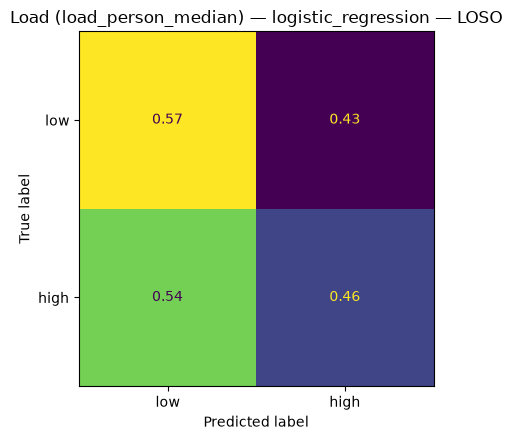

In [15]:
plot_confusion(load_predictions[(MAIN_LOAD_LABEL, BEST_LOAD_MODEL, "loso")], ["low", "high"],
               f"Load ({MAIN_LOAD_LABEL}) — {BEST_LOAD_MODEL} — LOSO", "load_confusion_loso.png")

## 7. Final models (trained on all participants)

The final models are tuned with `GroupKFold` over all 25 participants and then trained on all modelling rows.
These are the models the app uses; the LOSO numbers above estimate how well they work for a **new** person.

In [16]:
def train_final_model(model_name: str, table: pd.DataFrame, target: str):
    """
    Tune (GroupKFold over participants) and train one model on all modelling rows.

    In:  model name, feature table, label column.
    Out: (fitted pipeline with predict_proba, chosen hyperparameters).
    """
    return fit_tuned_model(
        model_name, table[FEATURE_NAMES], table[target],
        inner_cv=GroupKFold(n_splits=INNER_FOLDS), inner_groups=table["participant"], for_export=True,
    )


condition_model, condition_model_parameters = train_final_model(BEST_CONDITION_MODEL, main_table, "condition")
load_model, load_model_parameters = train_final_model(BEST_LOAD_MODEL, main_table, MAIN_LOAD_LABEL)
print("Condition model:", BEST_CONDITION_MODEL, condition_model_parameters, "classes:", list(condition_model.classes_))
print("Load model:     ", BEST_LOAD_MODEL, load_model_parameters, "classes:", list(load_model.classes_))

Condition model: random_forest {'model__min_samples_leaf': 5} classes: ['interruptions', 'neutral', 'time_pressure']
Load model:      logistic_regression {'model__C': 0.1} classes: ['high', 'low']


## 8. Explainability (SHAP)

SHAP values show how much each feature pushed a prediction towards each class. Tree models use the fast
`TreeExplainer`; other models use a sampling-based explainer. We explain a random sample of rows with the final models.

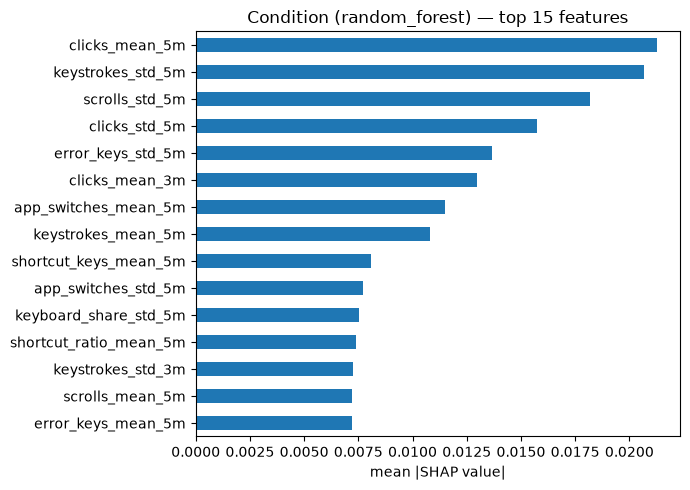

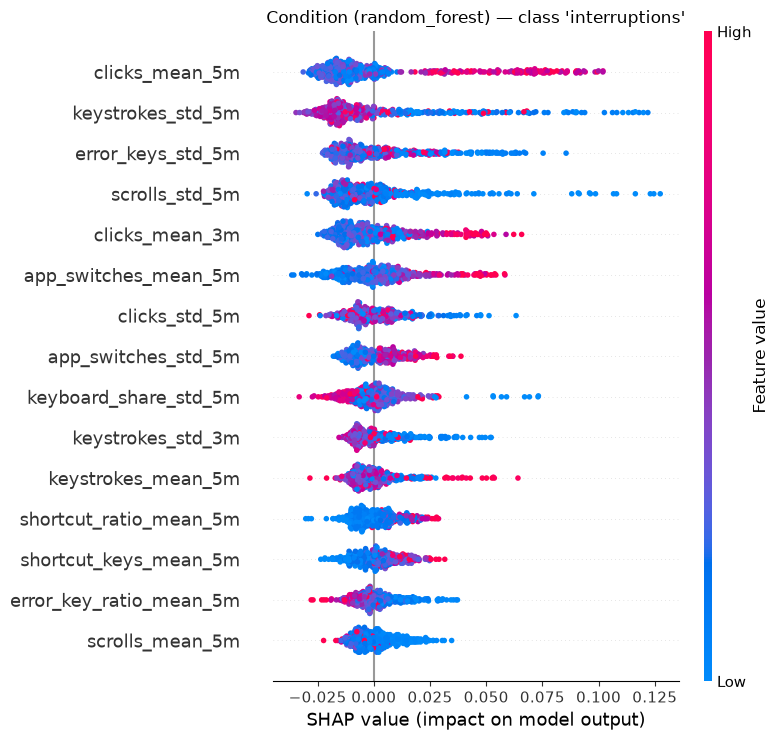

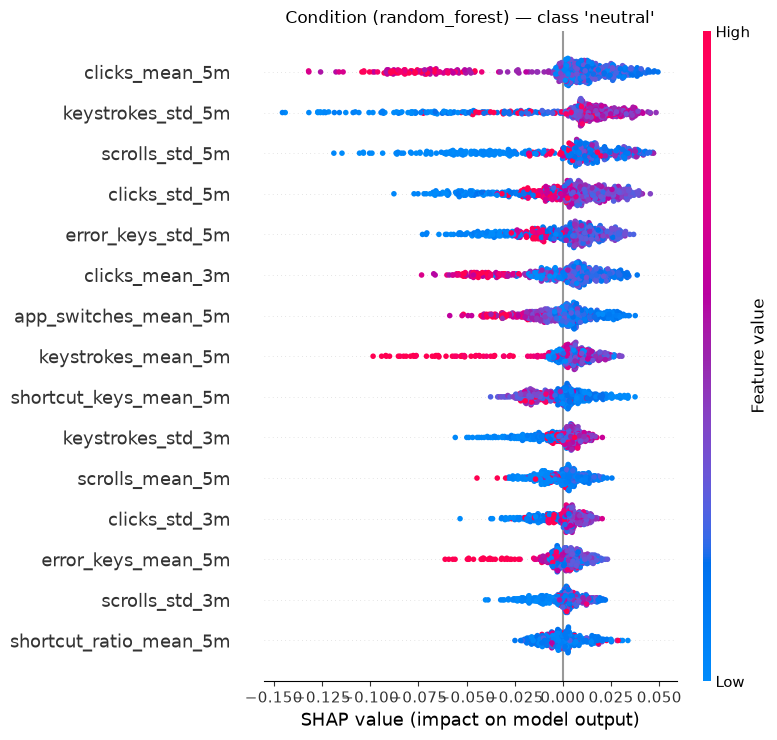

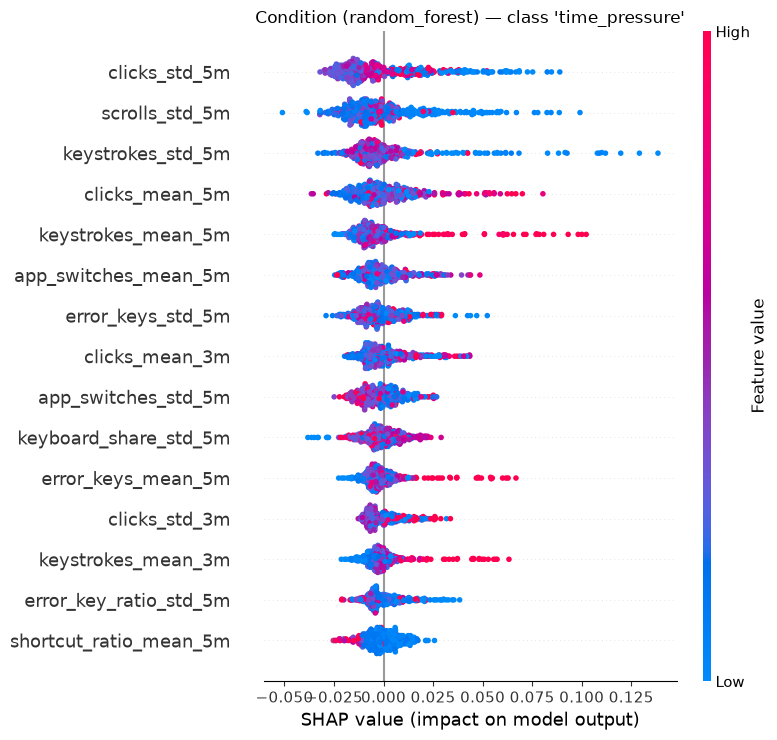

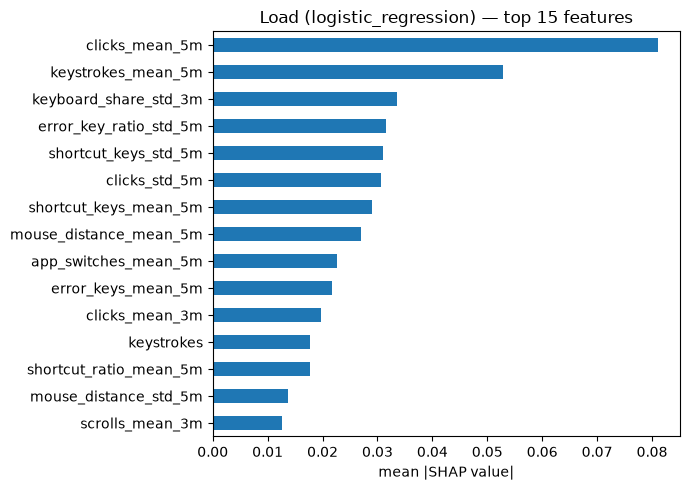

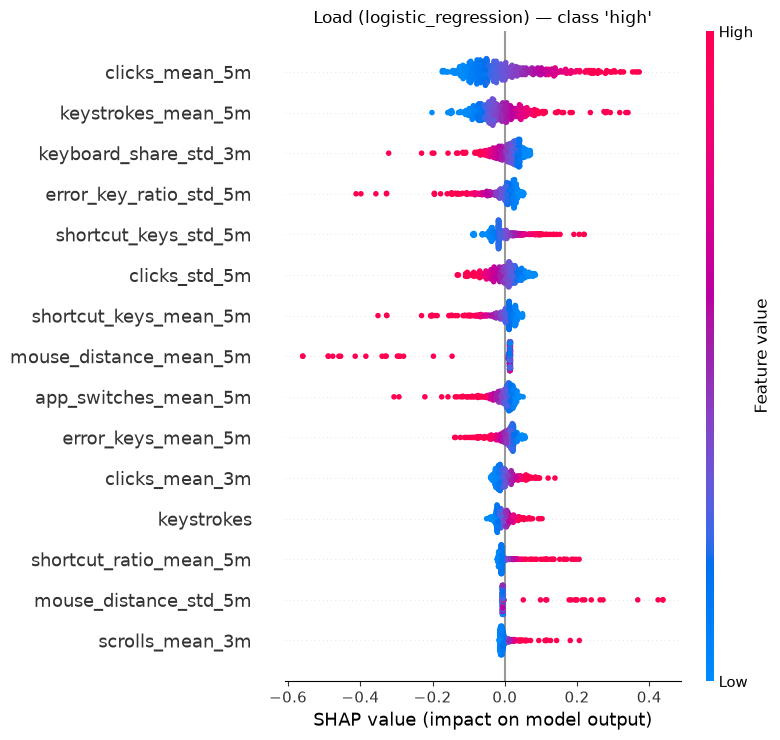

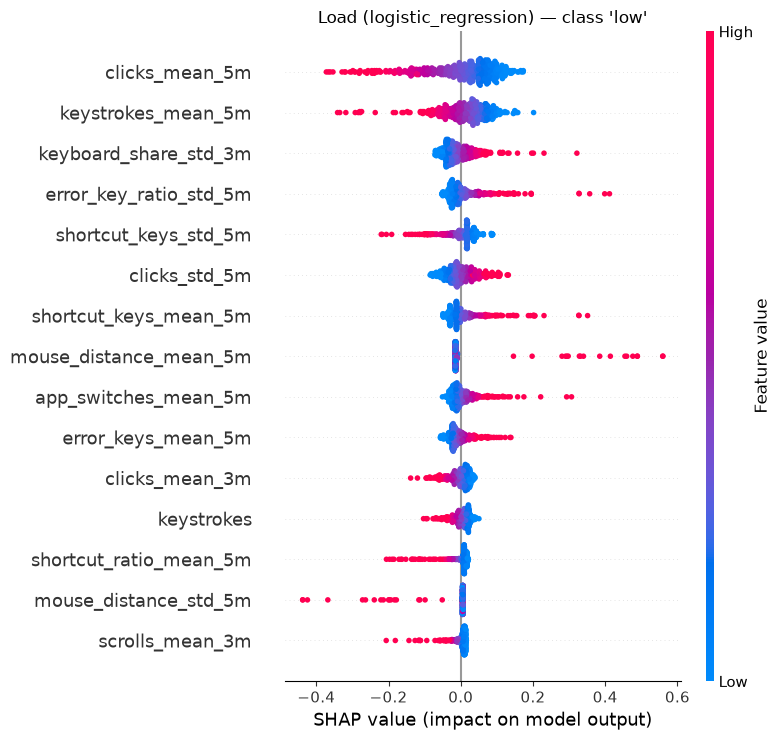

Top condition features: ['clicks_mean_5m', 'keystrokes_std_5m', 'scrolls_std_5m', 'clicks_std_5m', 'error_keys_std_5m', 'clicks_mean_3m', 'app_switches_mean_5m', 'keystrokes_mean_5m']
Top load features:      ['clicks_mean_5m', 'keystrokes_mean_5m', 'keyboard_share_std_3m', 'error_key_ratio_std_5m', 'shortcut_keys_std_5m', 'clicks_std_5m', 'shortcut_keys_mean_5m', 'mouse_distance_mean_5m']


In [17]:
def shap_values_per_class(pipeline: Pipeline, X_sample: pd.DataFrame, X_background: pd.DataFrame) -> dict:
    """
    Compute SHAP values for each class of a fitted pipeline.

    In:  fitted pipeline, the rows to explain, background rows (only used for non-tree models).
    Out: {class name: array of shape (rows, features)}.
    Why: SHAP returns different shapes for different model types; this hides that.
    """
    final_model = pipeline.named_steps["model"]
    classes = list(final_model.classes_)

    if isinstance(final_model, (RandomForestClassifier, LGBMClassifier)):
        # Tree models: exact and fast. (They have no scaler step, so X_sample is their input.)
        values = shap.TreeExplainer(final_model).shap_values(X_sample)
    else:
        # Other models: explain the whole pipeline's probabilities.
        masker = shap.maskers.Independent(X_background, max_samples=SHAP_BACKGROUND_ROWS)
        values = shap.Explainer(pipeline.predict_proba, masker, seed=RANDOM_SEED)(X_sample).values

    if isinstance(values, list):          # older SHAP format: one array per class
        values = np.stack(values, axis=2)
    values = np.asarray(values)
    if values.ndim == 2:                  # binary tree model: one array for the second class
        return {classes[1]: values}
    return {name: values[:, :, index] for index, name in enumerate(classes)}


def save_shap_plots(values_per_class: dict, X_sample: pd.DataFrame, prefix: str, title: str) -> pd.Series:
    """
    Save an overall importance bar chart and one beeswarm chart per class.

    In:  output of shap_values_per_class, the explained rows, a file prefix and a title.
    Out: mean |SHAP| per feature (averaged over classes), largest first.
    """
    # Overall importance = mean absolute SHAP value, averaged over classes.
    importance = pd.Series(
        np.mean([np.abs(v).mean(axis=0) for v in values_per_class.values()], axis=0), index=X_sample.columns
    ).sort_values(ascending=False)

    figure, axis = plt.subplots(figsize=(7, 5))
    importance.head(SHAP_TOP_FEATURES)[::-1].plot(kind="barh", ax=axis)
    axis.set_xlabel("mean |SHAP value|")
    axis.set_title(f"{title} — top {SHAP_TOP_FEATURES} features")
    figure.tight_layout()
    figure.savefig(REPORTS_DIR / f"{prefix}_shap_summary.png", dpi=150)
    plt.show()

    # One beeswarm per class: red = high feature value, blue = low.
    for class_name, values in values_per_class.items():
        shap.summary_plot(values, X_sample, max_display=SHAP_TOP_FEATURES, show=False)
        plt.title(f"{title} — class '{class_name}'")
        plt.tight_layout()
        plt.savefig(REPORTS_DIR / f"{prefix}_shap_{class_name}.png", dpi=150)
        plt.show()
    return importance


X_all = main_table[FEATURE_NAMES]
X_sample = X_all.sample(n=min(SHAP_SAMPLE_ROWS, len(X_all)), random_state=RANDOM_SEED)
X_background = X_all.sample(n=min(SHAP_BACKGROUND_ROWS, len(X_all)), random_state=RANDOM_SEED + 1)

condition_importance = save_shap_plots(
    shap_values_per_class(condition_model, X_sample, X_background), X_sample, "condition", f"Condition ({BEST_CONDITION_MODEL})"
)
load_importance = save_shap_plots(
    shap_values_per_class(load_model, X_sample, X_background), X_sample, "load", f"Load ({BEST_LOAD_MODEL})"
)
print("Top condition features:", list(condition_importance.head(8).index))
print("Top load features:     ", list(load_importance.head(8).index))

## 9. Export models, `features.json` and `model_card.md`

In [18]:
joblib.dump(condition_model, MODELS_DIR / "condition_model.pkl")
joblib.dump(load_model, MODELS_DIR / "load_model.pkl")

feature_spec = {
    "feature_names": FEATURE_NAMES,
    "raw_count_columns": F.RAW_COUNT_COLUMNS,
    "rolling_windows_minutes": list(F.DEFAULT_ROLLING_WINDOWS),
    "idle_definition": "a minute is idle when " + " + ".join(F.INPUT_COLUMNS_FOR_IDLE) + " == 0",
    "normalisation": {
        "method": "per-person z-score: (value - baseline mean) / baseline std",
        "baseline": "the user's first N active (non-idle) minutes",
        "calibration_active_minutes": CALIBRATION_ACTIVE_MINUTES,
        "zero_std_replacement": F.ZERO_STD_REPLACEMENT,
        "code": "shared/features.py: select_calibration_minutes, compute_baseline, apply_baseline",
    },
    "condition_model": {
        "file": "condition_model.pkl",
        "algorithm": BEST_CONDITION_MODEL,
        "hyperparameters": condition_model_parameters,
        "classes": [str(c) for c in condition_model.classes_],
    },
    "load_model": {
        "file": "load_model.pkl",
        "algorithm": BEST_LOAD_MODEL,
        "hyperparameters": load_model_parameters,
        "label": MAIN_LOAD_LABEL,
        "classes": [str(c) for c in load_model.classes_],
        "load_score": "100 x predict_proba column of class 'high'",
    },
    "training_data": {
        "dataset": "SWELL-KW computer-interaction features (uLog, per minute)",
        "participants": int(main_table["participant"].nunique()),
        "rows": int(len(main_table)),
    },
    "library_versions": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "lightgbm": lightgbm.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
    "created": date.today().isoformat(),
}
(MODELS_DIR / "features.json").write_text(json.dumps(feature_spec, indent=2))
print("Saved models and features.json to", MODELS_DIR)

Saved models and features.json to /Users/matrix/Desktop/Commit/shared/models


In [19]:
def markdown_table(table: pd.DataFrame) -> str:
    """Turn a small DataFrame into a Markdown table (no extra library needed)."""
    header = "| " + " | ".join(str(c) for c in table.columns) + " |"
    divider = "|" + "---|" * len(table.columns)
    rows = ["| " + " | ".join(str(v) for v in row) + " |" for row in table.itertuples(index=False)]
    return "\n".join([header, divider, *rows])


def result_row(results: pd.DataFrame, **conditions) -> pd.Series:
    """Pick exactly one row of a results table, e.g. result_row(t, model="lightgbm", scheme="loso")."""
    mask = np.ones(len(results), dtype=bool)
    for column, value in conditions.items():
        mask &= results[column] == value
    assert mask.sum() == 1, conditions
    return results[mask].iloc[0]


best_condition_loso = result_row(condition_results, model=BEST_CONDITION_MODEL, scheme="loso")
majority_condition_loso = result_row(condition_results, model="majority", scheme="loso")
best_load_loso = result_row(load_results, model=BEST_LOAD_MODEL, scheme="loso", target=MAIN_LOAD_LABEL)
majority_load_loso = result_row(load_results, model="majority", scheme="loso", target=MAIN_LOAD_LABEL)

model_card = f"""# Model card — Commit condition and load models

Generated by `ml/notebooks/03_models.ipynb` on {date.today().isoformat()}.

## Purpose
* **Condition model** (`condition_model.pkl`): predicts whether a person is working under **neutral**, **interruptions** or **time_pressure** conditions from one minute of computer-interaction counts (plus 3/5-minute history).
* **Load model** (`load_model.pkl`): predicts **low / high** self-rated mental effort. The app's load score = 100 x P(high).

Gentle, private self-help suggestions only. **Not** a medical tool. Must not be used for employee monitoring, appraisal, hiring or exams.

## Training data
* SWELL-KW (Koldijk et al., 2014), computer-interaction (uLog) per-minute features only; 25 participants, office tasks in a lab in the Netherlands. Licence CC-BY-NC-SA-4.0.
* Rows: {len(main_table)} active minutes (idle minutes and each person's first {CALIBRATION_ACTIVE_MINUTES} active "calibration" minutes removed; 31 logger-crash minutes and 2 broken rows removed in Notebook 1).
* Condition label = experimental condition. Load label = RSME mental-effort rating, one per participant per condition, split at each participant's own median (`{MAIN_LOAD_LABEL}`).

## Features ({len(FEATURE_NAMES)})
Counts our agent logs too: {", ".join(F.RAW_COUNT_COLUMNS)}; ratios: {", ".join(F.RATIO_COLUMNS)};
3- and 5-minute trailing rolling mean/std and idle share. All z-scored against the person's first {CALIBRATION_ACTIVE_MINUTES} active minutes.
Exact names and order: `features.json`. Code: `shared/features.py`.

## Results (leave-one-subject-out, mean ± std over 25 test people)

| Model | Target | macro-F1 | balanced accuracy | accuracy |
|---|---|---|---|---|
| {BEST_CONDITION_MODEL} | condition (3 classes) | {best_condition_loso.macro_f1_mean:.3f} ± {best_condition_loso.macro_f1_std:.3f} | {best_condition_loso.balanced_accuracy_mean:.3f} ± {best_condition_loso.balanced_accuracy_std:.3f} | {best_condition_loso.accuracy_mean:.3f} ± {best_condition_loso.accuracy_std:.3f} |
| majority baseline | condition | {majority_condition_loso.macro_f1_mean:.3f} ± {majority_condition_loso.macro_f1_std:.3f} | {majority_condition_loso.balanced_accuracy_mean:.3f} ± {majority_condition_loso.balanced_accuracy_std:.3f} | {majority_condition_loso.accuracy_mean:.3f} ± {majority_condition_loso.accuracy_std:.3f} |
| {BEST_LOAD_MODEL} | load (low/high) | {best_load_loso.macro_f1_mean:.3f} ± {best_load_loso.macro_f1_std:.3f} | {best_load_loso.balanced_accuracy_mean:.3f} ± {best_load_loso.balanced_accuracy_std:.3f} | {best_load_loso.accuracy_mean:.3f} ± {best_load_loso.accuracy_std:.3f} |
| majority baseline | load | {majority_load_loso.macro_f1_mean:.3f} ± {majority_load_loso.macro_f1_std:.3f} | {majority_load_loso.balanced_accuracy_mean:.3f} ± {majority_load_loso.balanced_accuracy_std:.3f} | {majority_load_loso.accuracy_mean:.3f} ± {majority_load_loso.accuracy_std:.3f} |

### Condition: all models, LOSO vs random 10-fold (random splits over-estimate performance on new people)
{markdown_table(condition_table)}

### Ablations (condition, {BEST_CONDITION_MODEL}, LOSO)
{markdown_table(ablation_table)}

### Load: all models
{markdown_table(load_table)}

### Stressed (I or T) vs neutral, for comparison with Koldijk et al. (65.51 % accuracy vs 61.76 % baseline, random 10-fold)
{markdown_table(stressed_table)}

Most important features (SHAP, condition): {", ".join(condition_importance.head(8).index)}.

## Limitations
1. **Computer-only signals are weak.** Compare every number with the majority baseline; per-person scores vary a lot (`ml/reports/condition_per_participant.csv`).
2. **Condition is confounded with time.** In SWELL the neutral block always came first, so "neutral" also means "start of the session"; part of what the model learns may be time-on-task.
3. **The condition is a proxy for load.** Only 13 of 25 participants rated neutral as their lowest-effort block.
4. **Load labels are coarse:** one rating per block, so only 75 labelled blocks; the per-person median split gives at most one "high" block per person.
5. **Doubtful labels:** PP12 and PP21 did not see the interruption e-mails; their interruption blocks were kept.
6. **Feature mismatches with the live app:** SWELL's error keys include Ctrl+Z and its shortcut count is a fixed list; mouse distance units differ by screen. Per-person z-scores reduce, but do not remove, these differences.
7. **Small lab dataset** (25 people, Netherlands, 2012). Expect lower accuracy on real-world work; personal calibration is essential.
8. **Model selection:** the best model was chosen by its LOSO score, which makes that score slightly optimistic.
9. **The load model is weak.** Under LOSO its balanced accuracy is {best_load_loso.balanced_accuracy_mean:.3f} (0.5 = chance). Treat the load score as a starting point that must be personalised with the user's own check-in ratings (README 8.5).

## Versions
Python {platform.python_version()}, scikit-learn {sklearn.__version__}, LightGBM {lightgbm.__version__}. The app must use the same scikit-learn and LightGBM versions to load the `.pkl` files.
"""
(MODELS_DIR / "model_card.md").write_text(model_card)
print("Saved model_card.md")

Saved model_card.md


## Summary

See `shared/models/model_card.md` for the final numbers. The key tables and charts are in `ml/reports/`:

* `condition_loso_vs_random.csv/.png` — all models, LOSO vs random 10-fold, with the majority baseline
* `condition_confusion_loso.png`, `condition_confusion_random.png`, `condition_per_participant.csv/.png`
* `stressed_results.csv` — binary comparison with the original paper
* `condition_ablations.csv` — ablation studies
* `load_results.csv`, `load_confusion_loso.png`
* `condition_shap_*.png`, `load_shap_*.png`